In [ ]:
!nvidia-smi

Sun Oct 12 12:32:16 2025       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 550.54.15              Driver Version: 550.54.15      CUDA Version: 12.4     |
|-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   77C    P0             32W /   70W |    3432MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
from google.colab import auth
auth.authenticate_user()


In [ ]:
%%writefile data_utils.py

import torch.utils.data as data
import torch
from PIL import Image
import numpy as np
import os
import os.path
import json
import io # To handle image bytes in memory
from google.cloud import storage

# --- GCS Configuration ---
# Your specific bucket name
GCS_BUCKET_NAME = 'kaveri-amazon-bin-dataset-unique'
# Define the paths to the folders inside your GCS bucket
IMAGE_GCS_FOLDER = 'data/Images/'
INPUT_GCS_FOLDER = 'data/input/'

# Initialize GCS client and bucket once for efficiency
# These will be re-initialized periodically within the class
GCS_CLIENT = None
GCS_BUCKET = None

# --- MODIFIED: Add a threshold for client re-initialization ---
GCS_CLIENT_REINIT_THRESHOLD = 500

def _reinitialize_gcs_client():
    """Re-initializes the global GCS client and bucket."""
    global GCS_CLIENT, GCS_BUCKET
    print("Re-initializing GCS client...")
    GCS_CLIENT = storage.Client()
    GCS_BUCKET = GCS_CLIENT.bucket(GCS_BUCKET_NAME)
    print("GCS client re-initialized.")


def gcs_image_loader(image_path_suffix):
    """
    Custom loader to download image bytes from GCS and open with PIL.
    Periodically re-initializes GCS client.
    """
    global GCS_CLIENT, GCS_BUCKET # Need global access

    # --- MODIFIED: Re-initialize client if needed ---
    if GCS_CLIENT is None or ImageFolderCounting.image_load_count % GCS_CLIENT_REINIT_THRESHOLD == 0:
        _reinitialize_gcs_client()

    try:
        blob = GCS_BUCKET.blob(image_path_suffix)
        img_bytes = blob.download_as_bytes()
        # --- MODIFIED: Increment counter ---
        ImageFolderCounting.image_load_count += 1
        return Image.open(io.BytesIO(img_bytes)).convert('RGB')
    except Exception as e:
        print(f"Error loading image from GCS at {image_path_suffix}: {e}")
        # Return a black dummy image on failure (224x224 placeholder)
        # --- MODIFIED: Increment counter even on failure ---
        ImageFolderCounting.image_load_count += 1
        return Image.new('RGB', (224, 224), color = 'black')

class ImageFolderCounting(data.Dataset):
    # --- MODIFIED: Add image load counter ---
    image_load_count = 0

    def __init__(self, list_file, transform=None, target_transform=None):

        # --- MODIFIED: Ensure client is initialized on dataset creation ---
        if GCS_CLIENT is None:
             _reinitialize_gcs_client()


        # --- MODIFIED: Load list_file from GCS ---
        # list_file is expected to be a JSON file like 'counting_train.json'
        list_file_path = os.path.join(INPUT_GCS_FOLDER, list_file)
        print(f'Attempting to load data_list json file from GCS: {list_file_path}') # Added print

        try:
            blob = GCS_BUCKET.blob(list_file_path)
            data_content = blob.download_as_string() # Get content as string
            data_list = json.loads(data_content)
            print(f'Successfully loaded {len(data_list)} items from {list_file}') # Added print
        except Exception as e:
            print(f'ERROR: Failed to load data_list from GCS at {list_file_path}: {e}') # Modified print
            data_list = []

        print('Finished attempting to load data_list json file.') # Modified print

        self.root = IMAGE_GCS_FOLDER # We use the general path to the Images folder
        self.transform = transform
        self.target_transform = target_transform
        self.data_list = data_list
        self.N = len(self.data_list)
        print(f'ImageFolderCounting dataset initialized with {self.N} samples.') # Added print


    def __getitem__(self, index):
        # pick up the image
        item = self.data_list[index]
        target = int(item[1])

        # Construct the full GCS path suffix for the image
        img_path_suffix = os.path.join(self.root, f'%05d.jpg' % (item[0]+1))

        # --- MODIFIED: Use the GCS loader ---
        img = gcs_image_loader(img_path_suffix)

        if self.transform is not None:
            img = self.transform(img)
        if self.target_transform is not None:
            target = self.target_transform(target)

        return img, target

    def __len__(self):
        return self.N

Writing data_utils.py


In [ ]:
gcs_bucket_name = 'kaveri-amazon-bin-dataset-unique'
input_gcs_folder = 'data/input/'
image_gcs_folder = 'data/Images/'

In [ ]:
%%writefile data_utils.py

import torch.utils.data as data
import torch
from PIL import Image
import numpy as np
import os
import os.path
import json
import io # To handle image bytes in memory
from google.cloud import storage

# --- GCS Configuration ---
# Your specific bucket name
GCS_BUCKET_NAME = 'kaveri-amazon-bin-dataset-unique'
# Define the paths to the folders inside your GCS bucket
IMAGE_GCS_FOLDER = 'data/Images/'
INPUT_GCS_FOLDER = 'data/input/'

# Initialize GCS client and bucket once for efficiency
# These will be re-initialized periodically within the class
GCS_CLIENT = None
GCS_BUCKET = None

# --- MODIFIED: Add a threshold for client re-initialization ---
GCS_CLIENT_REINIT_THRESHOLD = 500

def _reinitialize_gcs_client():
    """Re-initializes the global GCS client and bucket."""
    global GCS_CLIENT, GCS_BUCKET
    print("Re-initializing GCS client...")
    GCS_CLIENT = storage.Client()
    GCS_BUCKET = GCS_CLIENT.bucket(GCS_BUCKET_NAME)
    print("GCS client re-initialized.")


def gcs_image_loader(image_path_suffix):
    """
    Custom loader to download image bytes from GCS and open with PIL.
    Periodically re-initializes GCS client.
    """
    global GCS_CLIENT, GCS_BUCKET # Need global access

    # --- MODIFIED: Re-initialize client if needed ---
    if GCS_CLIENT is None or ImageFolderCounting.image_load_count % GCS_CLIENT_REINIT_THRESHOLD == 0:
        _reinitialize_gcs_client()

    try:
        blob = GCS_BUCKET.blob(image_path_suffix)
        img_bytes = blob.download_as_bytes()
        # --- MODIFIED: Increment counter ---
        ImageFolderCounting.image_load_count += 1
        return Image.open(io.BytesIO(img_bytes)).convert('RGB')
    except Exception as e:
        print(f"Error loading image from GCS at {image_path_suffix}: {e}")
        # Return a black dummy image on failure (224x224 placeholder)
        # --- MODIFIED: Increment counter even on failure ---
        ImageFolderCounting.image_load_count += 1
        return Image.new('RGB', (224, 224), color = 'black')

class ImageFolderCounting(data.Dataset):
    # --- MODIFIED: Add image load counter ---
    image_load_count = 0

    def __init__(self, list_file, transform=None, target_transform=None):

        # --- MODIFIED: Ensure client is initialized on dataset creation ---
        if GCS_CLIENT is None:
             _reinitialize_gcs_client()


        # --- MODIFIED: Load list_file from GCS ---
        # list_file is expected to be a JSON file like 'counting_train.json'
        list_file_path = os.path.join(INPUT_GCS_FOLDER, list_file)
        print(f'Attempting to load data_list json file from GCS: {list_file_path}') # Added print

        try:
            blob = GCS_BUCKET.blob(list_file_path)
            data_content = blob.download_as_string() # Get content as string
            data_list = json.loads(data_content)
            print(f'Successfully loaded {len(data_list)} items from {list_file}') # Added print
        except Exception as e:
            print(f'ERROR: Failed to load data_list from GCS at {list_file_path}: {e}') # Modified print
            data_list = []

        print('Finished attempting to load data_list json file.') # Modified print

        self.root = IMAGE_GCS_FOLDER # We use the general path to the Images folder
        self.transform = transform
        self.target_transform = target_transform
        self.data_list = data_list
        self.N = len(self.data_list)
        print(f'ImageFolderCounting dataset initialized with {self.N} samples.') # Added print


    def __getitem__(self, index):
        # pick up the image
        item = self.data_list[index]
        target = int(item[1])

        # Construct the full GCS path suffix for the image
        img_path_suffix = os.path.join(self.root, f'%05d.jpg' % (item[0]+1))

        # --- MODIFIED: Use the GCS loader ---
        img = gcs_image_loader(img_path_suffix)

        if self.transform is not None:
            img = self.transform(img)
        if self.target_transform is not None:
            target = self.target_transform(target)

        return img, target

    def __len__(self):
        return self.N

Overwriting data_utils.py


**RESNET 18**




In [ ]:
import argparse
import os
import shutil
import time

import torch
import torch.nn as nn
import torch.nn.parallel
import torch.backends.cudnn as cudnn
import torch.optim
import torch.utils.data
import torchvision.transforms as transforms
import torchvision.models as models

# --- MODIFIED: ADD GCS IMPORTS ---
from google.cloud import storage
# --- MODIFIED: Import ImageFolderCounting at the beginning ---
from data_utils import ImageFolderCounting

import numpy as np
from PIL import Image

# --- MODIFIED: GCS CONFIGURATION ---
GCS_BUCKET_NAME = 'kaveri-amazon-bin-dataset-unique'
INPUT_GCS_FOLDER = 'data/input/'
IMAGE_GCS_FOLDER = 'data/Images/'

# Initialize GCS client and bucket (Global access for data_utils)
# Note: These need to be accessible within data_utils, usually done via passing them or setting global environment.
# For simplicity in this script, we'll configure the GCS client where needed, or rely on the configuration
# done globally in the Colab session (as was done in the corrected data_utils).

model_names = sorted(name for name in models.__dict__
    if name.islower() and not name.startswith("__")
    and callable(models.__dict__[name]))


parser = argparse.ArgumentParser(description='PyTorch ABID Counting')
# The 'data' argument is not used correctly in the original script, so we'll ignore it.
parser.add_argument('data', metavar='DIR', help='path to dataset')
parser.add_argument('--arch', '-a', metavar='ARCH', default='resnet34', choices=model_names, help='model architecture: ' + ' | '.join(model_names) + ' (default: resnet34)')
parser.add_argument('-j', '--workers', default=8, type=int, metavar='N', help='number of data loading workers (default: 4)')
parser.add_argument('--epochs', default=40, type=int, metavar='N', help='number of total epochs to run')
parser.add_argument('--start-epoch', default=0, type=int, metavar='N', help='manual epoch number (useful on restarts)')
parser.add_argument('-b', '--batch_size', default=128, type=int, metavar='N', help='mini-batch size (default: 256)')
parser.add_argument('--lr', '--learning-rate', default=0.1, type=float, metavar='LR', help='initial learning rate')
parser.add_argument('--lrd','--learning-rate-decay-step', default=10, type=int, metavar='N', help='learning rate decay epoch')
parser.add_argument('--momentum', default=0.9, type=float, metavar='M', help='momentum')
parser.add_argument('--weight-decay', '--wd', default=1e-4, type=float, metavar='W', help='weight decay (default: 1e-4)')
parser.add_argument('--print-freq', '-p', default=10, type=int, metavar='N', help='print frequency (default: 10)')
parser.add_argument('--resume', default='', type=str, metavar='PATH', help='path to latest checkpoint (default: none)')
parser.add_argument('--evaluate', default=False, type=bool, metavar='BOOL', help='evaluate or train')
parser.add_argument('--save-model-id', default=1, type=int, metavar='N', help='id of the model to be saved')
parser.add_argument('--lastlayer', default=False, type=bool, metavar='BOOL', help='last layer or full network')

# ... (show_image function and best_prec variable remain the same) ...
def show_image(im,target):
    print('count: %d' % target[0])
    npimg = np.transpose(im[0].mul(255).byte().numpy(), (1,2,0))
    img_batch = npimg
    for idx in range(5):
        print('count : %d' % target[idx+1])
        npimg = np.transpose(im[idx+1].mul(255).byte().numpy(), (1,2,0))
        img_batch = np.concatenate((img_batch,npimg), axis=0)
    img_pair_disp = Image.fromarray(img_batch)
    img_pair_disp.show()

best_prec = 0
train_loss_list = []
val_acc_list= []
train_acc_list = []

def main():
    global args, best_prec, train_loss_list, val_acc_list, train_acc_list
    # NOTE: In a Colab cell, you usually don't call parser.parse_args() directly.
    # We will simulate the arguments directly inside the script for easy execution.
    # args = parser.parse_args()

    # --- SIMULATE ARGUMENTS FOR COLAB EXECUTION ---
    class ColabArgs:
        def __init__(self):
            self.arch = 'resnet18' # Start with ResNet18 for baseline
            self.epochs = 15 # Run for a reasonable number of epochs
            self.start_epoch = 0
            self.batch_size = 64
            self.lr = 0.01
            self.lrd = 10
            self.momentum = 0.9
            self.weight_decay = 1e-3
            self.print_freq = 10
            self.resume = ''
            self.evaluate = False
            self.save_model_id = 1
            self.lastlayer = False
            self.workers = 2 # Lower number of workers is often better in Colab

    args = ColabArgs()
    # ---------------------------------------------

    # create model
    print("=> creating model '{}'".format(args.arch))
    net = models.__dict__[args.arch]()

    # The model architecture section remains largely the same.
    in_features = net.fc.in_features
    new_fc = nn.Linear(in_features,6) # Output classes 0-5 (6 total)
    net.fc = new_fc

    net.cuda() # Moves model to GPU

    # ... (optionally resume from a checkpoint remains the same, but GCS-compatible paths would be needed for snapshots) ...
    # Skip snapshot saving/loading for this initial run.

    cudnn.benchmark = True

    # Data loading code
    normalize = transforms.Normalize(mean=[0.485, 0.456, 0.406],
                                     std=[0.229, 0.224, 0.225])

    # --- MODIFIED: Pass only the JSON filename to the ImageFolderCounting class ---
    train_loader = torch.utils.data.DataLoader(
        ImageFolderCounting(
            list_file='counting_train.json',
            transform=transforms.Compose([
                transforms.Resize((224, 224)), # Added missing resize
                transforms.RandomHorizontalFlip(),
                transforms.ToTensor(),
                normalize,
            ])
        ),
        batch_size=args.batch_size, shuffle=True,
        num_workers=args.workers, pin_memory=True)

    val_loader = torch.utils.data.DataLoader(
        ImageFolderCounting(
            list_file='counting_val.json',
            transform=transforms.Compose([
                transforms.Resize((224, 224)), # Added missing resize
                transforms.ToTensor(),
                normalize,
            ])
        ),
        batch_size=args.batch_size, shuffle=False,
        num_workers=args.workers, pin_memory=True)

    # define loss function (criterion) and optimizer
    criterion = nn.CrossEntropyLoss().cuda()

    optimizer = torch.optim.SGD(net.parameters(), args.lr, # Changed `params` to `net.parameters()`
                                 momentum=args.momentum,
                                 weight_decay=args.weight_decay)

    # evaluate on validation set
    if args.evaluate == True:
        validate(val_loader, net, criterion, True)
        return

    for epoch in range(args.start_epoch, args.epochs):
        # train for one epoch
        train(train_loader, net, criterion, optimizer, epoch)

        # evaluate on validation set
        prec = validate(val_loader, net, criterion, False)

        # ... (saving checkpoint logic remains, but requires GCS setup to save the file) ...
        is_best = prec > best_prec
        best_prec = max(prec, best_prec)
        print(f"Epoch {epoch} finished. Best Validation Accuracy: {best_prec:.4f}")

# ... (train, validate, AverageMeter, adjust_learning_rate functions remain the same) ...

def train(train_loader, net, criterion, optimizer, epoch):
    cur_lr = adjust_learning_rate(optimizer, epoch)
    batch_time = AverageMeter()
    data_time = AverageMeter()
    losses = AverageMeter()
    train_acc = AverageMeter()
    net.train()
    end = time.time()
    for i, (input, target) in enumerate(train_loader):
        data_time.update(time.time() - end)
        target = target.cuda()
        input = input.cuda()
        input_var = torch.autograd.Variable(input)
        target_var = torch.autograd.Variable(target)
        output = net(input_var)
        loss = criterion(output, target_var)
        score,idx = torch.max(output.data,1)
        correct = (target==idx)
        acc = float(correct.sum())/input.size(0)
        # Note: The original code used loss.data[0], which is deprecated. Using loss.item()
        losses.update(loss.item(), input.size(0))
        train_acc.update(acc, input.size(0))
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        batch_time.update(time.time() - end)
        end = time.time()

        # Original script used python 2 style printing, updated for Colab readability
        if i % args.print_freq == 0:
             print('Epoch: [{0}][{1}/{2}] lr {cur_lr:.5f}\tLoss {loss.val:.4f} ({loss.avg:.4f})\tPrec {train_acc.val:.3f} ({train_acc.avg:.3f})'.format(
                epoch, i, len(train_loader), cur_lr=cur_lr, loss=losses, train_acc=train_acc))

        train_loss_list.append(losses.val)
    train_acc_list.append(train_acc.avg)

def validate(val_loader, net, criterion, file_out):
    batch_time = AverageMeter()
    losses = AverageMeter()
    val_acc = AverageMeter()
    net.eval()

    # Note: File saving needs GCS implementation, skipping for simplicity here.

    end = time.time()
    for i, (input, target) in enumerate(val_loader):
        with torch.no_grad():
            target = target.cuda()
            input = input.cuda()
            input_var = torch.autograd.Variable(input)
            target_var = torch.autograd.Variable(target)

            output = net(input_var)
            loss = criterion(output, target_var)

            score,idx = torch.max(output.data,1)
            correct = (target==idx)
            acc = float(correct.sum())/input.size(0)

            # losses.update(loss.data[0], input.size(0)) # Deprecated
            losses.update(loss.item(), input.size(0))
            val_acc.update(acc, input.size(0))

            batch_time.update(time.time() - end)
            end = time.time()

            # Original script used python 2 style printing, updated for Colab readability
            if i % args.print_freq == 0:
                 print('Test: [{0}/{1}]\tLoss {loss.val:.4f} ({loss.avg:.4f})\tPrec {val_acc.val:.3f} ({val_acc.avg:.3f})'.format(
                    i, len(val_loader), loss=losses, val_acc=val_acc))

    print(' * Prec {val_acc.avg:.3f}'.format(val_acc=val_acc))

    val_acc_list.append(val_acc.avg)
    return val_acc.avg


class AverageMeter(object):
    """Computes and stores the average and current value"""
    def __init__(self):
        self.reset()

    def reset(self):
        self.val = 0
        self.avg = 0
        self.sum = 0
        self.count = 0

    def update(self, val, n=1):
        self.val = val
        self.sum += val * n
        self.count += n
        self.avg = self.sum / self.count


def adjust_learning_rate(optimizer, epoch):
    """Sets the learning rate to the initial LR decayed by 1/10 every args.lrd epochs"""
    lr = args.lr * (0.1 ** (epoch // args.lrd))
    for param_group in optimizer.param_groups:
        param_group['lr'] = lr
    return lr

if __name__ == '__main__':
    main()

=> creating model 'resnet18'
Attempting to load data_list json file from GCS: data/input/counting_train.json
Successfully loaded 263 items from counting_train.json
Finished attempting to load data_list json file.
ImageFolderCounting dataset initialized with 263 samples.
Attempting to load data_list json file from GCS: data/input/counting_val.json
Successfully loaded 72 items from counting_val.json
Finished attempting to load data_list json file.
ImageFolderCounting dataset initialized with 72 samples.
Re-initializing GCS client...
Re-initializing GCS client...
GCS client re-initialized.
GCS client re-initialized.
Epoch: [0][0/5] lr 0.01000	Loss 2.1417 (2.1417)	Prec 0.219 (0.219)
Re-initializing GCS client...
Re-initializing GCS client...
GCS client re-initialized.
GCS client re-initialized.
Test: [0/2]	Loss 1.6038 (1.6038)	Prec 0.297 (0.297)
 * Prec 0.292
Epoch 0 finished. Best Validation Accuracy: 0.2917
Re-initializing GCS client...
Re-initializing GCS client...
GCS client re-initial

**RESNET 34** - SGD optimizer

In [ ]:
# --- INSTALL & AUTHENTICATE ---
# Run this cell if you haven't already installed these packages or authenticated
# !pip install torch torchvision torchaudio google-cloud-storage scikit-learn pandas opencv-python
# from google.colab import auth
# auth.authenticate_user()
# -----------------------------

import argparse
import os
import shutil
import time
import torch
import torch.nn as nn
import torch.nn.parallel
import torch.backends.cudnn as cudnn
import torch.optim
import torch.utils.data
import torchvision.transforms as transforms
import torchvision.models as models

# Import the fixed data loader (must be defined in a prior cell or written to data_utils.py)
from data_utils import ImageFolderCounting

import numpy as np
from PIL import Image

# --- SIMULATE ARGUMENTS FOR COLAB EXECUTION ---
class ColabArgs:
    def __init__(self):
        self.arch = 'resnet34'       # <--- RESNET34 MODEL
        self.epochs = 15
        self.start_epoch = 0
        self.batch_size = 64
        self.lr = 0.01              # Learning Rate (consistent with good practice for small sets)
        self.lrd = 10               # Learning Rate Decay Step
        self.momentum = 0.9
        self.weight_decay = 0.01    # Regularization (1e-2, used in the paper's ResNet34 setup)
        self.print_freq = 10
        self.resume = ''
        self.evaluate = False
        self.save_model_id = 4
        self.lastlayer = False
        self.workers = 2

args = ColabArgs()
# ---------------------------------------------

# Global lists for tracking loss and accuracy
best_prec = 0
train_loss_list = []
val_acc_list= []
train_acc_list = []

# Dummy definition for placeholder functions (must be defined later in the script scope)
def adjust_learning_rate(optimizer, epoch):
    lr = args.lr * (0.1 ** (epoch // args.lrd))
    for param_group in optimizer.param_groups:
        param_group['lr'] = lr
    return lr

# The AverageMeter class is crucial for tracking metrics
class AverageMeter(object):
    def __init__(self):
        self.reset()
    def reset(self):
        self.val = 0
        self.avg = 0
        self.sum = 0
        self.count = 0
    def update(self, val, n=1):
        self.val = val
        self.sum += val * n
        self.count += n
        self.avg = self.sum / self.count

# --- Training Loop ---
def train(train_loader, net, criterion, optimizer, epoch):
    cur_lr = adjust_learning_rate(optimizer, epoch)
    batch_time = AverageMeter()
    data_time = AverageMeter()
    losses = AverageMeter()
    train_acc = AverageMeter()
    net.train()
    end = time.time()
    for i, (input, target) in enumerate(train_loader):
        data_time.update(time.time() - end)
        target = target.cuda() # Send target to GPU
        input = input.cuda()   # Send input to GPU
        input_var = torch.autograd.Variable(input)
        target_var = torch.autograd.Variable(target)
        output = net(input_var)
        loss = criterion(output, target_var)
        score,idx = torch.max(output.data,1)
        correct = (target==idx)
        acc = float(correct.sum())/input.size(0)
        losses.update(loss.item(), input.size(0))
        train_acc.update(acc, input.size(0))
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        batch_time.update(time.time() - end)
        end = time.time()
        if i % args.print_freq == 0:
             print('Epoch: [{0}][{1}/{2}] lr {cur_lr:.5f}\tLoss {loss.val:.4f} ({loss.avg:.4f})\tPrec {train_acc.val:.3f} ({train_acc.avg:.3f})'.format(
                epoch, i, len(train_loader), cur_lr=cur_lr, loss=losses, train_acc=train_acc))
        train_loss_list.append(losses.val)
    train_acc_list.append(train_acc.avg)

# --- Validation Loop ---
def validate(val_loader, net, criterion, file_out):
    batch_time = AverageMeter()
    losses = AverageMeter()
    val_acc = AverageMeter()
    net.eval()
    end = time.time()
    for i, (input, target) in enumerate(val_loader):
        with torch.no_grad():
            target = target.cuda()
            input = input.cuda()
            input_var = torch.autograd.Variable(input)
            target_var = torch.autograd.Variable(target)
            output = net(input_var)
            loss = criterion(output, target_var)
            score,idx = torch.max(output.data,1)
            correct = (target==idx)
            acc = float(correct.sum())/input.size(0)
            losses.update(loss.item(), input.size(0))
            val_acc.update(acc, input.size(0))
            batch_time.update(time.time() - end)
            end = time.time()
            if i % args.print_freq == 0:
                 print('Test: [{0}/{1}]\tLoss {loss.val:.4f} ({loss.avg:.4f})\tPrec {val_acc.val:.3f} ({val_acc.avg:.3f})'.format(
                    i, len(val_loader), loss=losses, val_acc=val_acc))

    print(' * Prec {val_acc.avg:.3f}'.format(val_acc=val_acc))
    val_acc_list.append(val_acc.avg)
    return val_acc.avg

# --- Main Function ---
def main():
    global args, best_prec, train_loss_list, val_acc_list, train_acc_list

    # --- CREATE MODEL ---
    print("=> creating model '{}'".format(args.arch))
    net = models.__dict__[args.arch](weights=models.ResNet34_Weights.IMAGENET1K_V1) # Use pretrained ImageNet weights

    # Modify the final layer for 6 classes (0-5 items)
    in_features = net.fc.in_features
    new_fc = nn.Linear(in_features, 6)
    net.fc = new_fc
    net.cuda() # Move model to GPU

    cudnn.benchmark = True # Speeds up training on fixed input size

    # --- DATA LOADING ---
    normalize = transforms.Normalize(mean=[0.485, 0.456, 0.406],
                                     std=[0.229, 0.224, 0.225])

    transform_list = transforms.Compose([
                transforms.Resize((224, 224)),
                transforms.RandomHorizontalFlip(),
                transforms.ToTensor(),
                normalize,
            ])

    val_transform_list = transforms.Compose([
                transforms.Resize((224, 224)),
                transforms.ToTensor(),
                normalize,
            ])

    train_loader = torch.utils.data.DataLoader(
        ImageFolderCounting(list_file='counting_train.json', transform=transform_list),
        batch_size=args.batch_size, shuffle=True, num_workers=args.workers, pin_memory=True)

    val_loader = torch.utils.data.DataLoader(
        ImageFolderCounting(list_file='counting_val.json', transform=val_transform_list),
        batch_size=args.batch_size, shuffle=False, num_workers=args.workers, pin_memory=True)

    # --- LOSS & OPTIMIZER ---
    criterion = nn.CrossEntropyLoss().cuda()

    optimizer = torch.optim.SGD(net.parameters(), args.lr,
                                 momentum=args.momentum,
                                 weight_decay=args.weight_decay)

    # --- TRAINING LOOP ---
    for epoch in range(args.start_epoch, args.epochs):
        train(train_loader, net, criterion, optimizer, epoch)
        prec = validate(val_loader, net, criterion, False)

        is_best = prec > best_prec
        best_prec = max(prec, best_prec)
        print(f"Epoch {epoch} finished. Best Validation Accuracy: {best_prec:.4f}")

    print("\nCNN Experiment COMPLETE.")

if __name__ == '__main__':
    # NOTE: PyTorch uses the main guard, so we call main() here.
    main()

=> creating model 'resnet34'
Attempting to load data_list json file from GCS: data/input/counting_train.json
Successfully loaded 263 items from counting_train.json
Finished attempting to load data_list json file.
ImageFolderCounting dataset initialized with 263 samples.
Attempting to load data_list json file from GCS: data/input/counting_val.json
Successfully loaded 72 items from counting_val.json
Finished attempting to load data_list json file.
ImageFolderCounting dataset initialized with 72 samples.
Re-initializing GCS client...
Re-initializing GCS client...
GCS client re-initialized.
GCS client re-initialized.
Epoch: [0][0/5] lr 0.01000	Loss 2.0276 (2.0276)	Prec 0.078 (0.078)
Re-initializing GCS client...
Re-initializing GCS client...
GCS client re-initialized.GCS client re-initialized.

Test: [0/2]	Loss 1.6893 (1.6893)	Prec 0.109 (0.109)
 * Prec 0.139
Epoch 0 finished. Best Validation Accuracy: 0.1389
Re-initializing GCS client...
Re-initializing GCS client...
GCS client re-initial

**RESNET 34-** ADAM OPTIMIZER

In [ ]:
# --- INSTALL & AUTHENTICATE ---
# NOTE: Run this cell only if you need to redefine your helper functions
# from data_utils import ImageFolderCounting
# import time, torch, etc.
# -----------------------------

import sys
sys.path.append('/content') # Add the directory containing data_utils.py to the Python path

import argparse
import os
import shutil
import time
import torch
import torch.nn as nn
import torch.nn.parallel
import torch.backends.cudnn as cudnn
import torch.optim
import torch.utils.data
import torchvision.transforms as transforms
import torchvision.models as models
from data_utils import ImageFolderCounting
from google.cloud import storage
import numpy as np
from PIL import Image
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Define ColabArgs for Adam (GCS path definitions and helper classes remain the same)
class ColabArgs:
    def __init__(self):
        self.arch = 'resnet34'       # <--- RESNET34 MODEL
        self.epochs = 10
        self.start_epoch = 0
        self.batch_size = 64        # Reduced batch size for stability
        self.lr = 0.001             # ADAM Learning Rate (0.001)
        self.lrd = 30
        self.momentum = 0.9
        self.weight_decay = 0.0001  # ADAM Weight Decay (1e-4)
        self.print_freq = 10
        self.resume = ''
        self.evaluate = False
        self.save_model_id = 5
        self.workers = 2

args = ColabArgs()
best_prec = 0
# Initialize lists globally
train_loss_list = []
val_acc_list= []
train_acc_list = []
all_val_preds = []
all_val_targets = []

# --- MODIFIED: Moved helper functions and class outside of main ---

def adjust_learning_rate(optimizer, epoch):
    lr = args.lr * (0.1 ** (epoch // args.lrd))
    for param_group in optimizer.param_groups:
        param_group['lr'] = lr
    return lr

# The AverageMeter class is crucial for tracking metrics
class AverageMeter(object):
    """Computes and stores the average and current value"""
    def __init__(self):
        self.reset()
    def reset(self):
        self.val = 0
        self.avg = 0
        self.sum = 0
        self.count = 0
    def update(self, val, n=1):
        self.val = val
        self.sum += val * n
        self.count += n
        self.avg = self.sum / self.count

# --- Training Loop ---
def train(train_loader, net, criterion, optimizer, epoch):
    cur_lr = adjust_learning_rate(optimizer, epoch)
    batch_time = AverageMeter()
    data_time = AverageMeter()
    losses = AverageMeter()
    train_acc = AverageMeter()
    net.train()
    end = time.time()
    for i, (input, target) in enumerate(train_loader):
        data_time.update(time.time() - end)
        target = target.cuda() # Send target to GPU
        input = input.cuda()   # Send input to GPU
        input_var = torch.autograd.Variable(input)
        target_var = torch.autograd.Variable(target)
        output = net(input_var)
        loss = criterion(output, target_var)
        score,idx = torch.max(output.data,1)
        correct = (target==idx)
        acc = float(correct.sum())/input.size(0)
        losses.update(loss.item(), input.size(0))
        train_acc.update(acc, input.size(0))
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        batch_time.update(time.time() - end)
        end = time.time()
        if i % args.print_freq == 0:
             print('Epoch: [{0}][{1}/{2}] lr {cur_lr:.5f}\tLoss {loss.val:.4f} ({loss.avg:.4f})\tPrec {train_acc.val:.3f} ({train_acc.avg:.3f})'.format(
                epoch, i, len(train_loader), cur_lr=cur_lr, loss=losses, train_acc=train_acc))
        train_loss_list.append(losses.val)
    train_acc_list.append(train_acc.avg)

# --- MODIFIED VALIDATE FUNCTION ---
def validate(val_loader, net, criterion, file_out):
    batch_time = AverageMeter()
    losses = AverageMeter()
    val_acc = AverageMeter()
    net.eval()

    current_targets = []
    current_preds = []

    end = time.time()
    for i, (input, target) in enumerate(val_loader):
        with torch.no_grad():
            target = target.cuda()
            input = input.cuda()
            input_var = torch.autograd.Variable(input)
            target_var = torch.autograd.Variable(target)
            output = net(input_var)
            loss = criterion(output, target_var)
            score,idx = torch.max(output.data,1)
            correct = (target==idx)
            acc = float(correct.sum())/input.size(0)
            losses.update(loss.item(), input.size(0))
            val_acc.update(acc, input.size(0))

            # Collect targets and predictions for the confusion matrix
            current_targets.extend(target.cpu().numpy())
            current_preds.extend(idx.cpu().numpy())


            batch_time.update(time.time() - end)
            end = time.time()
            if i % args.print_freq == 0:
                 print('Test: [{0}/{1}]\tLoss {loss.val:.4f} ({loss.avg:.4f})\tPrec {val_acc.val:.3f} ({val_acc.avg:.3f})'.format(
                    i, len(val_loader), loss=losses, val_acc=val_acc))

    print(' * Prec {val_acc.avg:.3f}'.format(val_acc=val_acc))
    val_acc_list.append(val_acc.avg)

    # Return everything needed for analysis
    return val_acc.avg, current_preds, current_targets

# --- Main Function ---
def main():
    global args, best_prec, train_loss_list, val_acc_list, train_acc_list, all_val_preds, all_val_targets

    # --- CREATE MODEL ---
    print("=> creating model '{}'".format(args.arch))
    net = models.__dict__[args.arch](weights=models.ResNet34_Weights.IMAGENET1K_V1) # Use pretrained ImageNet weights

    # Modify the final layer for 6 classes (0-5 items)
    in_features = net.fc.in_features
    new_fc = nn.Linear(in_features, 6)
    net.fc = new_fc
    net.cuda() # Move model to GPU

    cudnn.benchmark = True # Speeds up training on fixed input size

    # --- DATA LOADING ---
    normalize = transforms.Normalize(mean=[0.485, 0.456, 0.406],
                                     std=[0.229, 0.224, 0.225])

    transform_list = transforms.Compose([
                transforms.Resize((224, 224)),
                transforms.RandomHorizontalFlip(),
                transforms.ToTensor(),
                normalize,
            ])

    val_transform_list = transforms.Compose([
                transforms.Resize((224, 224)),
                transforms.ToTensor(),
                normalize,
            ])

    train_loader = torch.utils.data.DataLoader(
        ImageFolderCounting(list_file='counting_train.json', transform=transform_list),
        batch_size=args.batch_size, shuffle=True, num_workers=args.workers, pin_memory=True)

    val_loader = torch.utils.data.DataLoader(
        ImageFolderCounting(list_file='counting_val.json', transform=val_transform_list),
        batch_size=args.batch_size, shuffle=False, num_workers=args.workers, pin_memory=True)

    # --- LOSS & OPTIMIZER (ADAM) ---
    criterion = nn.CrossEntropyLoss().cuda()

    # **CRITICAL CHANGE: ADAM OPTIMIZER**
    optimizer = torch.optim.Adam(net.parameters(), args.lr,
                                 weight_decay=args.weight_decay)

    # Reset lists at the beginning of training
    train_loss_list.clear()
    val_acc_list.clear()
    train_acc_list.clear()
    all_val_preds.clear()
    all_val_targets.clear()


    for epoch in range(args.start_epoch, args.epochs):
        # The GCS client refresh prints will appear in the train/validate functions
        train(train_loader, net, criterion, optimizer, epoch)

        # In your main() function's training loop
        val_prec, current_preds, current_targets = validate(val_loader, net, criterion, False)
        all_val_preds.extend(current_preds)
        all_val_targets.extend(current_targets)


        is_best = val_prec > best_prec
        best_prec = max(val_prec, best_prec)
        print(f"Epoch {epoch} finished. Best Validation Accuracy: {best_prec:.4f}")

    print("\nCNN Experiment COMPLETE.")
    # Removed return statement as lists are now global


if __name__ == '__main__':
    # NOTE: PyTorch uses the main guard, so we call main() here.
    main()

=> creating model 'resnet34'
Attempting to load data_list json file from GCS: data/input/counting_train.json
Successfully loaded 263 items from counting_train.json
Finished attempting to load data_list json file.
ImageFolderCounting dataset initialized with 263 samples.
Attempting to load data_list json file from GCS: data/input/counting_val.json
Successfully loaded 72 items from counting_val.json
Finished attempting to load data_list json file.
ImageFolderCounting dataset initialized with 72 samples.
Re-initializing GCS client...
Re-initializing GCS client...
GCS client re-initialized.
GCS client re-initialized.
Epoch: [0][0/5] lr 0.00100	Loss 2.1646 (2.1646)	Prec 0.109 (0.109)
Re-initializing GCS client...
Re-initializing GCS client...
GCS client re-initialized.
GCS client re-initialized.
Test: [0/2]	Loss 2.3713 (2.3713)	Prec 0.266 (0.266)
 * Prec 0.278
Epoch 0 finished. Best Validation Accuracy: 0.2778
Re-initializing GCS client...
Re-initializing GCS client...
GCS client re-initial

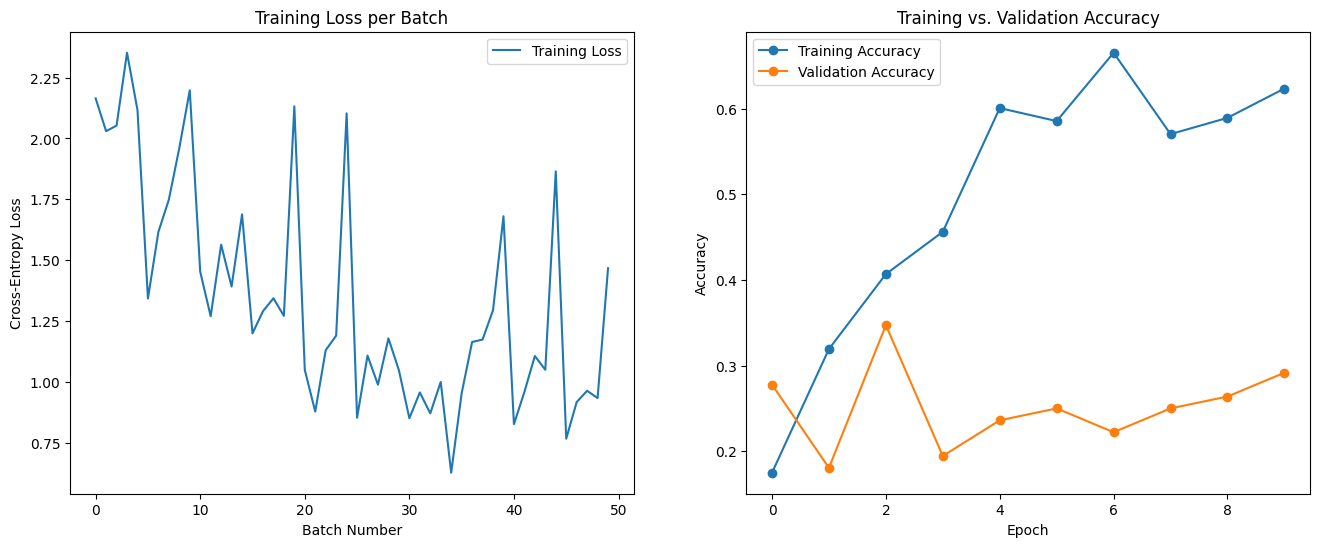


--- Final Validation Results ---


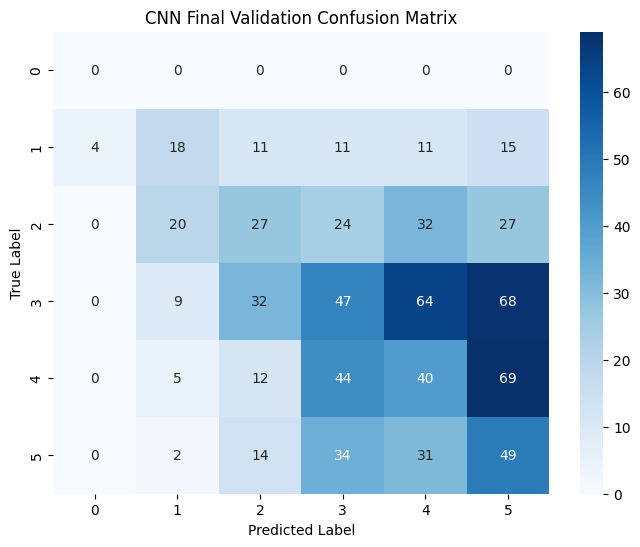

In [ ]:
# --- ADD THIS NEW CELL AT THE END OF YOUR CNN NOTEBOOK ---
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Make sure to run this cell AFTER your model has finished training

# Plotting the Training Loss and Accuracy Curves
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# 1. Plot Training Loss
ax1.plot(train_loss_list, label='Training Loss')
ax1.set_title('Training Loss per Batch')
ax1.set_xlabel('Batch Number')
ax1.set_ylabel('Cross-Entropy Loss')
ax1.legend()

# 2. Plot Accuracy Curves
# Note: These lists store the average accuracy for each epoch
epochs = range(len(train_acc_list))
ax2.plot(epochs, train_acc_list, label='Training Accuracy', marker='o')
ax2.plot(epochs, val_acc_list, label='Validation Accuracy', marker='o')
ax2.set_title('Training vs. Validation Accuracy')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Accuracy')
ax2.legend()
plt.show()


# 3. Plot the Confusion Matrix for the final epoch
print("\n--- Final Validation Results ---")
cm = confusion_matrix(all_val_targets, all_val_preds)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=range(6), yticklabels=range(6))
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('CNN Final Validation Confusion Matrix')
plt.show()